# Predicción de riesgo de enfermedad cardíaca con Machine Learning

**Ramo:** Fundamentos de Machine Learning · Duoc UC · 2025
**Docente:** Franco Jorquera P.
**Equipo:** Diego Arias Zavando · Raúl Olguín Romo

Proyecto de clasificación sobre el **Statlog (Heart) Dataset** de UCI siguiendo la metodología **CRISP-DM**: comprensión del problema, exploración y limpieza de datos, entrenamiento y optimización de tres modelos, evaluación con métricas clínicamente relevantes y un formulario interactivo para predecir nuevos casos.

> **Versión revisada para portafolio.** Respecto de la entrega original se corrigió lo siguiente:
> 1. El target venía como 1 = sano y 2 = enfermo, y scikit-learn toma la clase `1` como positiva por defecto: las métricas de *recall* y *F1* medían la detección de pacientes **sanos**. Ahora el target es `0 = ausencia` y `1 = presencia`.
> 2. El escalado se hacía antes de dividir los datos y los modelos se entrenaban con los datos sin escalar. Ahora el `StandardScaler` vive dentro de un `Pipeline`, se ajusta solo con el set de entrenamiento y el formulario aplica exactamente el mismo preprocesamiento.
> 3. Se agregó una **segunda iteración** con todas las variables clínicas, que mejora la detección de casos positivos.

## Índice
1. Librerías
2. Carga del dataset
3. Comprensión del negocio
4. Comprensión de los datos
5. Preparación de los datos
6. Modelado · Iteración 1 (8 variables)
7. Iteración 2 · Oportunidad de mejora (13 variables)
8. Evaluación y selección del modelo
9. Conclusiones y limitaciones
10. Despliegue: formulario interactivo

## 1. Librerías

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score)

sns.set_theme(style="whitegrid")
SEED = 42

## 2. Carga del dataset
Se descarga directamente desde el repositorio de UCI. Si no hay conexión, se lee la copia local `data/heart.dat`.

In [2]:
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/heart/heart.dat"
COLS = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
        'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

try:
    df = pd.read_csv("data/heart.dat", sep=r"\s+", names=COLS)
except FileNotFoundError:
    df = pd.read_csv(URL, sep=r"\s+", names=COLS)

# En el dataset original: 1 = ausencia, 2 = presencia de enfermedad cardíaca.
# Se recodifica para que la clase positiva (1) sea "presencia".
df['target'] = (df['target'] == 2).astype(int)

print("Dimensiones:", df.shape)
df.head()

Dimensiones: (270, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,70.0,1.0,4.0,130.0,322.0,0.0,2.0,109.0,0.0,2.4,2.0,3.0,3.0,1
1,67.0,0.0,3.0,115.0,564.0,0.0,2.0,160.0,0.0,1.6,2.0,0.0,7.0,0
2,57.0,1.0,2.0,124.0,261.0,0.0,0.0,141.0,0.0,0.3,1.0,0.0,7.0,1
3,64.0,1.0,4.0,128.0,263.0,0.0,0.0,105.0,1.0,0.2,2.0,1.0,7.0,0
4,74.0,0.0,2.0,120.0,269.0,0.0,2.0,121.0,1.0,0.2,1.0,1.0,3.0,0


## 3. Comprensión del negocio
Las enfermedades cardiovasculares son la principal causa de muerte en Chile y el mundo. En 2015 causaron el 27,5 % de las muertes en el país: un 30 % por ataques cerebrovasculares y un 29 % por infarto al miocardio. Aunque los infartos han disminuido en los últimos 20 años, la muerte prematura persiste. En 2018 las hospitalizaciones por esta causa llegaron a 11.399, con un promedio de 9,1 días, y afectan más a hombres (68,6 %) que a mujeres (31,4 %). ([Fuente: DIPRECE, MINSAL](https://diprece.minsal.cl/garantias-explicitas-en-salud-auge-o-ges/guias-de-practica-clinica/infarto-agudo-del-miocardio/descripcion-y-epidemiologia/))

**Objetivo:** entrenar un modelo que, a partir de variables clínicas básicas, estime si un paciente presenta enfermedad cardíaca, como apoyo a la priorización y derivación.

**Criterio de éxito:** en un contexto clínico un **falso negativo** (un enfermo clasificado como sano) es más grave que un falso positivo, por lo que se prioriza el **recall** de la clase positiva, equilibrado con el **F1-score**.

## 4. Comprensión de los datos
270 pacientes, 13 variables clínicas y una variable objetivo binaria, por lo que es un **problema de clasificación**.

| Variable | Descripción | Tipo |
|---|---|---|
| age | Edad en años | Numérica |
| sex | Sexo (1 = hombre, 0 = mujer) | Binaria |
| cp | Tipo de dolor torácico (1 = angina típica, 2 = atípica, 3 = no anginoso, 4 = asintomático) | Categórica |
| trestbps | Presión arterial en reposo (mm Hg) | Numérica |
| chol | Colesterol sérico (mg/dl) | Numérica |
| fbs | Glicemia en ayunas > 120 mg/dl (1 = sí) | Binaria |
| restecg | ECG en reposo (0 = normal, 1 = anomalía ST-T, 2 = hipertrofia ventricular izquierda) | Categórica |
| thalach | Frecuencia cardíaca máxima alcanzada | Numérica |
| exang | Angina inducida por ejercicio (1 = sí) | Binaria |
| oldpeak | Depresión del ST inducida por ejercicio respecto del reposo | Numérica |
| slope | Pendiente del ST en el peak de ejercicio (1 = ascendente, 2 = plana, 3 = descendente) | Categórica |
| ca | Número de vasos principales coloreados por fluoroscopía (0–3) | Numérica |
| thal | Talio (3 = normal, 6 = defecto fijo, 7 = defecto reversible) | Categórica |
| **target** | **0 = ausencia, 1 = presencia de enfermedad cardíaca** | **Binaria** |

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 270 entries, 0 to 269
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       270 non-null    float64
 1   sex       270 non-null    float64
 2   cp        270 non-null    float64
 3   trestbps  270 non-null    float64
 4   chol      270 non-null    float64
 5   fbs       270 non-null    float64
 6   restecg   270 non-null    float64
 7   thalach   270 non-null    float64
 8   exang     270 non-null    float64
 9   oldpeak   270 non-null    float64
 10  slope     270 non-null    float64
 11  ca        270 non-null    float64
 12  thal      270 non-null    float64
 13  target    270 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 29.7 KB


In [4]:
balance = df['target'].value_counts().rename({0: 'Ausencia (0)', 1: 'Presencia (1)'})
print(balance)
print(f"\nProporción de casos positivos: {df['target'].mean():.1%}")

target
Ausencia (0)     150
Presencia (1)    120
Name: count, dtype: int64

Proporción de casos positivos: 44.4%


Las clases están razonablemente balanceadas (56 % / 44 %), así que no es necesario re-muestrear. Igual se usa `stratify` al dividir para mantener la proporción.

## 5. Preparación de los datos
### 5.1 Selección de variables (iteración 1)
En la primera iteración se trabajó con 8 variables de obtención simple en una consulta: datos demográficos, signos vitales, laboratorio y ECG en reposo. Se dejaron fuera las que requieren prueba de esfuerzo o fluoroscopía (`cp`, `exang`, `oldpeak`, `slope`, `ca`).

In [5]:
FEATURES_V1 = ['age', 'sex', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'thal']
NUMERICAS = ['age', 'trestbps', 'chol', 'thalach']

df[NUMERICAS].describe().round(1)

,age,trestbps,chol,thalach
count,270.0,270.0,270.0,270.0
mean,54.4,131.3,249.7,149.7
std,9.1,17.9,51.7,23.2
min,29.0,94.0,126.0,71.0
25%,48.0,120.0,213.0,133.0
50%,55.0,130.0,245.0,153.5
75%,61.0,140.0,280.0,166.0
max,77.0,200.0,564.0,202.0


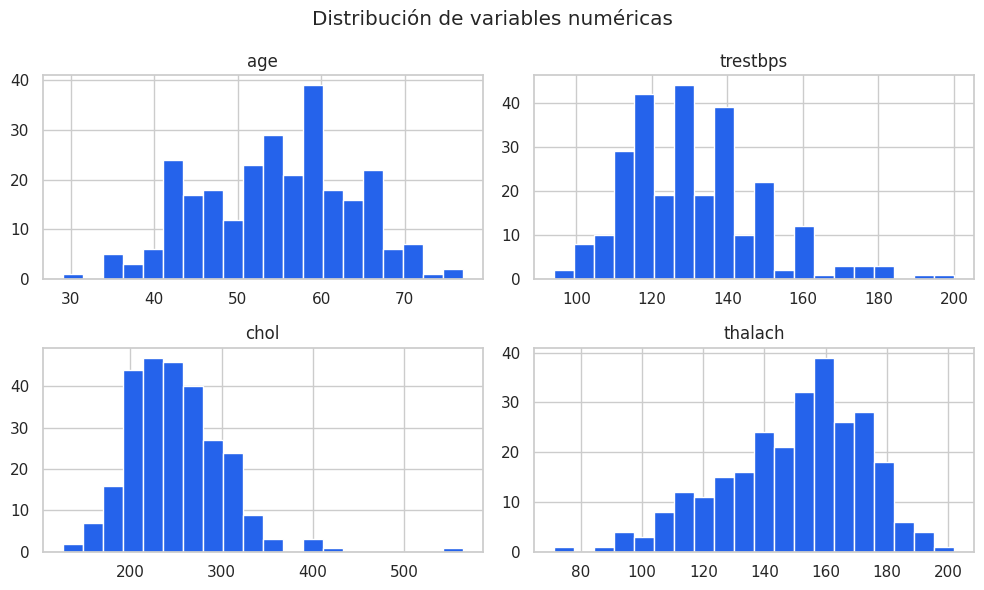

In [6]:
df[NUMERICAS].hist(figsize=(10, 6), bins=20, color="#2563EB", edgecolor="white")
plt.suptitle("Distribución de variables numéricas")
plt.tight_layout()
plt.show()

**Interpretación**
- **Edad:** el grupo más numeroso está cerca de los 60 años.
- **Presión arterial:** la mayoría está apenas sobre 125 mm Hg.
- **Colesterol:** se concentra entre 220 y 250 mg/dl.
- **Frecuencia cardíaca máxima:** la mayoría está entre 150 y 170 lpm.

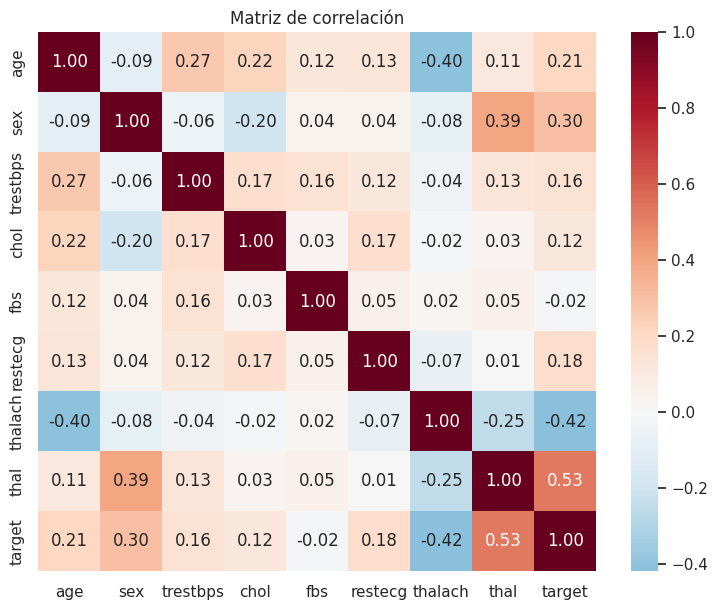

In [7]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[FEATURES_V1 + ['target']].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Matriz de correlación")
plt.show()

**Relaciones observadas:** a mayor edad, menor frecuencia cardíaca máxima (correlación negativa) y algo más de presión arterial. La frecuencia cardíaca máxima y `thal` son las variables de la iteración 1 más relacionadas con el target.

### 5.2 Valores fuera de rango y atípicos

In [8]:
# Valores imposibles (presión, colesterol o frecuencia en 0 o negativos)
df.query("age <= 0 or trestbps <= 0 or chol <= 0 or thalach <= 0")

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target


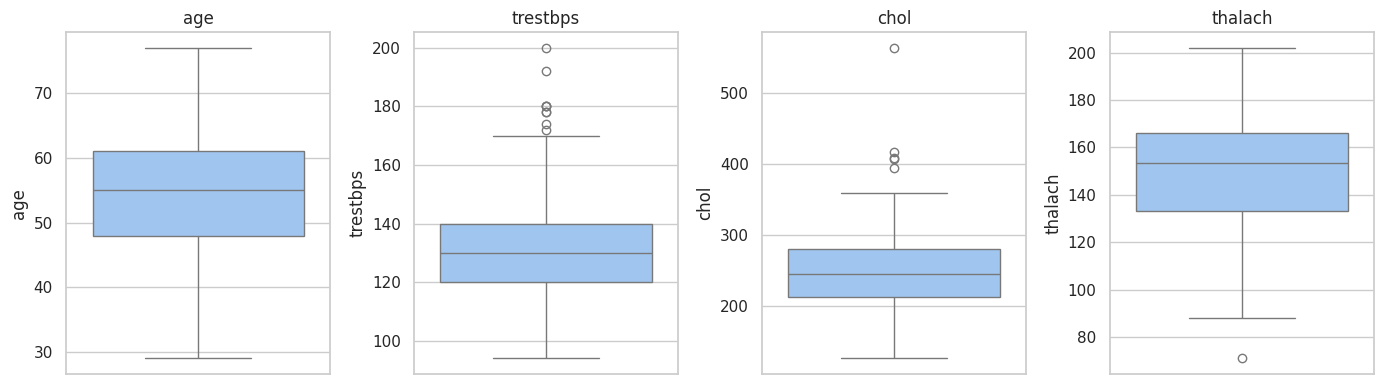

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, col in zip(axes, NUMERICAS):
    sns.boxplot(y=df[col], ax=ax, color="#93C5FD")
    ax.set_title(col)
plt.tight_layout()
plt.show()

No hay valores imposibles, pero sí atípicos: presión sobre 160 mm Hg, colesterol sobre 300 o bajo 150 mg/dl y frecuencia máxima bajo 100 lpm. Se eliminan para la iteración 1, como en la entrega original.

*Nota crítica:* en un contexto clínico esos valores pueden ser reales y justamente de pacientes de riesgo. Se mantiene la decisión para respetar el trabajo original, pero es un punto a revisar (ver limitaciones).

In [10]:
df_limpio = df.drop(df.query("trestbps > 160 or chol > 300 or thalach < 100 or chol < 150").index)
print(f"Registros: {len(df)} → {len(df_limpio)} ({len(df) - len(df_limpio)} eliminados)")

Registros: 270 → 209 (61 eliminados)


### 5.3 División entrenamiento / prueba
80 % entrenamiento y 20 % prueba, con `stratify` para mantener la proporción de clases y `random_state` para que sea reproducible.

In [11]:
def dividir(data, features):
    X = data[features]
    y = data['target']
    return train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)

X_train, X_test, y_train, y_test = dividir(df_limpio, FEATURES_V1)
print("Entrenamiento:", X_train.shape, "· Prueba:", X_test.shape)

Entrenamiento: (167, 8) · Prueba: (42, 8)


## 6. Modelado · Iteración 1
Se entrenan tres algoritmos, cada uno dentro de un `Pipeline` con `StandardScaler`, para que el escalado se ajuste solo con los datos de entrenamiento. Los hiperparámetros se buscan con `GridSearchCV` (validación cruzada estratificada de 5 pliegues) optimizando el **F1-score de la clase positiva**.

| Modelo | Por qué | Hiperparámetros explorados |
|---|---|---|
| Regresión Logística | Lineal e interpretable | `C`, `penalty` (L1/L2) |
| SVM | Separa clases con un hiperplano, lineal o con kernel RBF | `C`, `kernel`, `gamma` |
| Random Forest | Captura relaciones no lineales e indica importancia de variables | `n_estimators`, `max_depth`, `min_samples_split` |

In [12]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

MODELOS = {
    "Regresión Logística": (
        LogisticRegression(max_iter=1000, solver="liblinear"),
        {"clf__C": [0.001, 0.01, 0.1, 1, 10, 100], "clf__penalty": ["l1", "l2"]},
    ),
    "SVM": (
        SVC(probability=True, random_state=SEED),
        [{"clf__C": [0.01, 0.1, 1, 10, 100], "clf__kernel": ["linear"]},
         {"clf__C": [0.1, 1, 10, 100], "clf__gamma": [0.001, 0.01, 0.1, 1, "scale"], "clf__kernel": ["rbf"]}],
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=SEED),
        {"clf__n_estimators": [100, 200], "clf__max_depth": [None, 5, 8], "clf__min_samples_split": [2, 5, 10]},
    ),
}

def entrenar(X_train, y_train):
    mejores = {}
    for nombre, (modelo, grid) in MODELOS.items():
        pipe = Pipeline([("scaler", StandardScaler()), ("clf", modelo)])
        gs = GridSearchCV(pipe, grid, cv=CV, scoring="f1", n_jobs=-1).fit(X_train, y_train)
        mejores[nombre] = gs
        params = {k.replace("clf__", ""): v for k, v in gs.best_params_.items()}
        print(f"{nombre:<20} F1 (CV) = {gs.best_score_:.3f} · {params}")
    return mejores

def evaluar(mejores, X_test, y_test, titulo):
    filas = []
    fig, axes = plt.subplots(1, len(mejores), figsize=(15, 4))
    for ax, (nombre, gs) in zip(axes, mejores.items()):
        y_pred = gs.predict(X_test)
        filas.append({
            "Modelo": nombre,
            "F1 (CV)": round(gs.best_score_, 3),
            "Accuracy": round(accuracy_score(y_test, y_pred), 3),
            "Precision": round(precision_score(y_test, y_pred), 3),
            "Recall": round(recall_score(y_test, y_pred), 3),
            "F1 (test)": round(f1_score(y_test, y_pred), 3),
        })
        ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                               display_labels=["Ausencia", "Presencia"]).plot(ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(nombre)
        ax.grid(False)
        ax.set_xlabel("Predicción")
        ax.set_ylabel("Real")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(filas).sort_values("F1 (test)", ascending=False).reset_index(drop=True)

modelos_v1 = entrenar(X_train, y_train)

Regresión Logística  F1 (CV) = 0.757 · {'C': 0.01, 'penalty': 'l2'}


SVM                  F1 (CV) = 0.731 · {'C': 1, 'gamma': 0.1, 'kernel': 'rbf'}


Random Forest        F1 (CV) = 0.731 · {'max_depth': None, 'min_samples_split': 10, 'n_estimators': 100}


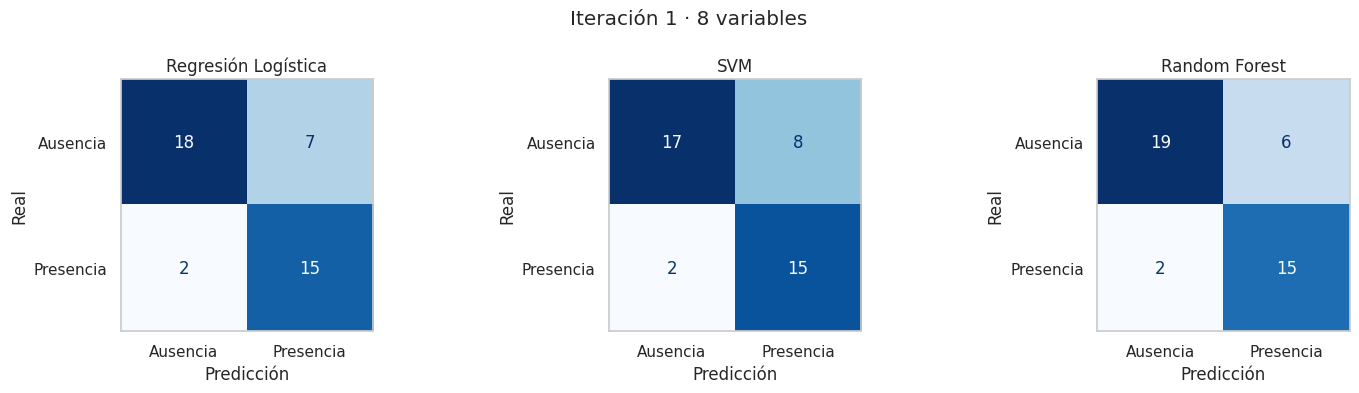

,Modelo,F1 (CV),Accuracy,Precision,Recall,F1 (test)
0,Random Forest,0.731,0.810,0.714,0.882,0.789
1,Regresión Logística,0.757,0.786,0.682,0.882,0.769
2,SVM,0.731,0.762,0.652,0.882,0.750


In [13]:
resultados_v1 = evaluar(modelos_v1, X_test, y_test, "Iteración 1 · 8 variables")
resultados_v1

**Cómo leer las métricas en este contexto**
- **Recall:** de los pacientes realmente enfermos, cuántos detecta el modelo. Es la métrica prioritaria.
- **Precision:** de los que el modelo marca como enfermos, cuántos lo están realmente.
- **F1-score:** equilibrio entre precision y recall.
- **Accuracy:** porcentaje total de aciertos. Con clases casi balanceadas es útil, pero no distingue el tipo de error.

## 7. Iteración 2 · Oportunidad de mejora
CRISP-DM es iterativo. Al volver a la fase de **preparación de datos** se revisó la selección de variables: las que se descartaron en la iteración 1 (`cp`, `exang`, `oldpeak`, `slope`, `ca`) son marcadores clínicos clásicos de cardiopatía isquémica. Se reentrena con las 13 variables, manteniendo la misma limpieza y división.

In [14]:
FEATURES_V2 = COLS[:-1]

X_train2, X_test2, y_train2, y_test2 = dividir(df_limpio, FEATURES_V2)
modelos_v2 = entrenar(X_train2, y_train2)

Regresión Logística  F1 (CV) = 0.812 · {'C': 0.001, 'penalty': 'l2'}


SVM                  F1 (CV) = 0.817 · {'C': 100, 'kernel': 'linear'}


Random Forest        F1 (CV) = 0.812 · {'max_depth': 5, 'min_samples_split': 10, 'n_estimators': 200}


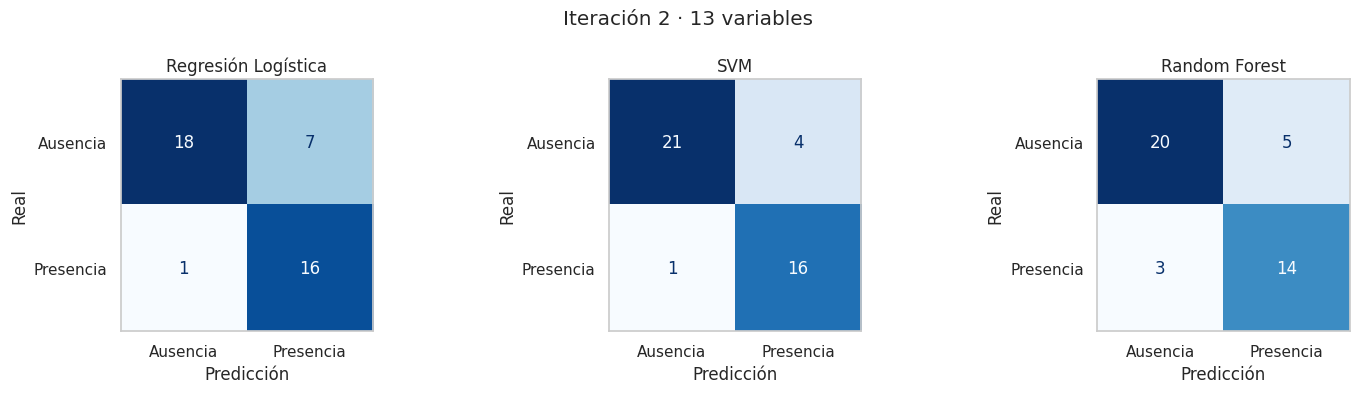

,Modelo,F1 (CV),Accuracy,Precision,Recall,F1 (test)
0,SVM,0.817,0.881,0.800,0.941,0.865
1,Regresión Logística,0.812,0.810,0.696,0.941,0.800
2,Random Forest,0.812,0.810,0.737,0.824,0.778


In [15]:
resultados_v2 = evaluar(modelos_v2, X_test2, y_test2, "Iteración 2 · 13 variables")
resultados_v2

## 8. Evaluación y selección del modelo

In [16]:
comparativa = pd.concat([
    resultados_v1.assign(Iteración="1 · 8 variables"),
    resultados_v2.assign(Iteración="2 · 13 variables"),
]).set_index(["Iteración", "Modelo"])
comparativa

F1 (CV)  Accuracy  Precision  Recall  \
Iteración        Modelo                                                      
1 · 8 variables  Random Forest          0.731     0.810      0.714   0.882   
                 Regresión Logística    0.757     0.786      0.682   0.882   
                 SVM                    0.731     0.762      0.652   0.882   
2 · 13 variables SVM                    0.817     0.881      0.800   0.941   
                 Regresión Logística    0.812     0.810      0.696   0.941   
                 Random Forest          0.812     0.810      0.737   0.824   

                                      F1 (test)  
Iteración        Modelo                          
1 · 8 variables  Random Forest            0.789  
                 Regresión Logística      0.769  
                 SVM                      0.750  
2 · 13 variables SVM                      0.865  
                 Regresión Logística      0.800  
                 Random Forest            0.778

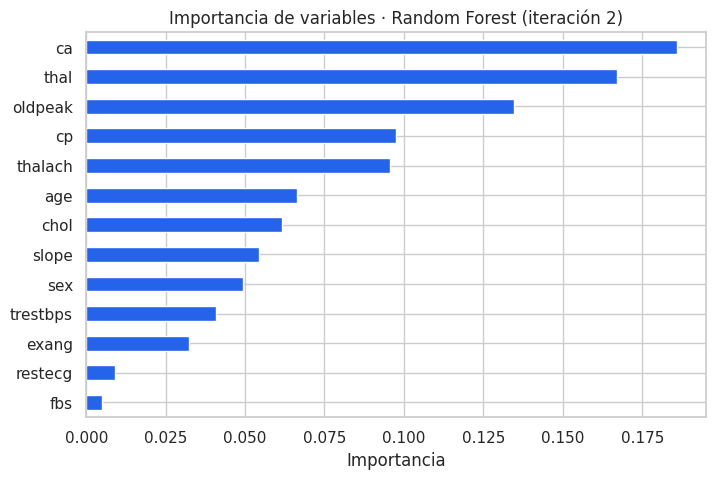

In [17]:
# Variables más influyentes según el Random Forest de la iteración 2
rf = modelos_v2["Random Forest"].best_estimator_.named_steps["clf"]
importancia = pd.Series(rf.feature_importances_, index=FEATURES_V2).sort_values()
importancia.plot.barh(figsize=(8, 5), color="#2563EB")
plt.title("Importancia de variables · Random Forest (iteración 2)")
plt.xlabel("Importancia")
plt.show()

In [18]:
# Selección: mejor F1 en validación cruzada de la iteración 2 (más estable que 42 casos de prueba)
mejor_nombre = max(modelos_v2, key=lambda n: modelos_v2[n].best_score_)
modelo_final = modelos_v2[mejor_nombre].best_estimator_
print("Modelo seleccionado:", mejor_nombre)
print(classification_report(y_test2, modelo_final.predict(X_test2), target_names=["Ausencia", "Presencia"]))

Modelo seleccionado: SVM
              precision    recall  f1-score   support

    Ausencia       0.95      0.84      0.89        25
   Presencia       0.80      0.94      0.86        17

    accuracy                           0.88        42
   macro avg       0.88      0.89      0.88        42
weighted avg       0.89      0.88      0.88        42



## 9. Conclusiones y limitaciones
- **Agregar las variables de esfuerzo y fluoroscopía mejora el desempeño.** La iteración 2 supera a la 1 en F1 y recall. El tipo de dolor torácico, la angina por ejercicio, la depresión del ST y el número de vasos comprometidos aportan información que los datos demográficos y de laboratorio no tienen.
- **Se prioriza el recall.** El modelo seleccionado detecta la gran mayoría de los pacientes enfermos del set de prueba, a costa de algunos falsos positivos, lo que es aceptable para una herramienta de tamizaje.
- **Limitaciones:**
  - El dataset tiene solo 270 registros (209 tras la limpieza), y el set de prueba, 42. Un caso más o menos mueve las métricas varios puntos. Por eso la selección se basa en la validación cruzada.
  - La eliminación de atípicos puede estar descartando a pacientes de alto riesgo. Una siguiente iteración debería compararla con modelos robustos a atípicos o con un recorte menos agresivo.
  - Los datos son de un único estudio de los años 80. Antes de cualquier uso real habría que validar con datos locales.

> Este modelo es un ejercicio académico y **no reemplaza el juicio clínico**.

## 10. Despliegue: formulario interactivo
Se guarda el `Pipeline` completo (escalado + modelo) con `joblib`, así el formulario aplica exactamente el mismo preprocesamiento que en el entrenamiento. La interfaz se construye con **Gradio**.

In [19]:
import joblib
joblib.dump(modelo_final, "modelo_cardiaco.pkl")
print("Modelo guardado: modelo_cardiaco.pkl")

Modelo guardado: modelo_cardiaco.pkl


In [20]:
# Ejecutar en Colab o en un entorno con gradio instalado:  pip install gradio
LANZAR_INTERFAZ = False  # cambiar a True para abrir el formulario

if LANZAR_INTERFAZ:
    import gradio as gr
    modelo = joblib.load("modelo_cardiaco.pkl")

    def predecir(age, sex, cp, trestbps, chol, fbs, restecg, thalach, exang, oldpeak, slope, ca, thal):
        fila = pd.DataFrame([[age, sex, cp, trestbps, chol, fbs, restecg, thalach, exang, oldpeak, slope, ca, thal]],
                            columns=FEATURES_V2)
        prob = modelo.predict_proba(fila)[0][1]
        if prob >= 0.5:
            return f"<h3 style='color:#dc2626;text-align:center'>Riesgo ALTO de enfermedad cardíaca ({prob:.0%})</h3>"
        return f"<h3 style='color:#16a34a;text-align:center'>Riesgo BAJO de enfermedad cardíaca ({prob:.0%})</h3>"

    with gr.Blocks(title="Predicción de enfermedad cardíaca") as app:
        gr.Markdown("# Predicción de riesgo de enfermedad cardíaca")
        with gr.Row():
            with gr.Column():
                gr.Markdown("### Paciente")
                age = gr.Slider(29, 77, value=55, step=1, label="Edad")
                sex = gr.Radio([("Mujer", 0), ("Hombre", 1)], value=1, label="Sexo")
                trestbps = gr.Slider(90, 200, value=130, step=1, label="Presión arterial en reposo (mm Hg)")
                chol = gr.Slider(120, 570, value=240, step=1, label="Colesterol (mg/dl)")
                fbs = gr.Radio([("No", 0), ("Sí", 1)], value=0, label="Glicemia en ayunas > 120 mg/dl")
                restecg = gr.Dropdown([("Normal", 0), ("Anomalía ST-T", 1), ("Hipertrofia VI", 2)], value=0, label="ECG en reposo")
            with gr.Column():
                gr.Markdown("### Prueba de esfuerzo y estudios")
                cp = gr.Dropdown([("Angina típica", 1), ("Angina atípica", 2), ("No anginoso", 3), ("Asintomático", 4)], value=4, label="Tipo de dolor torácico")
                thalach = gr.Slider(70, 205, value=150, step=1, label="Frecuencia cardíaca máxima")
                exang = gr.Radio([("No", 0), ("Sí", 1)], value=0, label="Angina inducida por ejercicio")
                oldpeak = gr.Slider(0, 6.5, value=1.0, step=0.1, label="Depresión del ST (oldpeak)")
                slope = gr.Dropdown([("Ascendente", 1), ("Plana", 2), ("Descendente", 3)], value=2, label="Pendiente del ST")
                ca = gr.Slider(0, 3, value=0, step=1, label="Vasos coloreados por fluoroscopía")
                thal = gr.Dropdown([("Normal", 3), ("Defecto fijo", 6), ("Defecto reversible", 7)], value=3, label="Talio")
        boton = gr.Button("Predecir", variant="primary")
        salida = gr.HTML()
        boton.click(predecir, [age, sex, cp, trestbps, chol, fbs, restecg, thalach, exang, oldpeak, slope, ca, thal], salida)
        gr.Markdown("*Ejercicio académico. No reemplaza la evaluación de un profesional de la salud.*")

    app.launch()